<a href="https://colab.research.google.com/github/swarnavadebnath/Football_Predictor/blob/main/FootballPredictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
from google.colab import userdata

# Securely load API keys
os.environ["KAGGLE_KEY"] = userdata.get('Kaggle_key')

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("adamgbor/club-football-match-data-2000-2025")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'club-football-match-data-2000-2025' dataset.
Path to dataset files: /kaggle/input/club-football-match-data-2000-2025


In [ ]:
os.listdir(path)

['Matches.csv', 'EloRatings.csv']

In [ ]:
import pandas as pd
file_path = os.path.join(path, 'Matches.csv')
# Explicitly specify 'HomeTeam' and 'AwayTeam' as string types to prevent unintended numeric conversion
df = pd.read_csv(file_path, dtype={'HomeTeam': str, 'AwayTeam': str})
df.head()

/tmp/ipykernel_900/2950626754.py:4: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, dtype={'HomeTeam': str, 'AwayTeam': str})


,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,...,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
0,F1,2000-07-28,NaN,Marseille,Troyes,1686.34,1586.57,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,F1,2000-07-28,NaN,Paris SG,Strasbourg,1714.89,1642.51,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,F2,2000-07-28,NaN,Wasquehal,Nancy,1465.08,1633.80,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,F1,2000-07-29,NaN,Auxerre,Sedan,1635.58,1624.22,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,F1,2000-07-29,NaN,Bordeaux,Metz,1734.34,1673.11,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import torch
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
import pandas as pd

# Define target and feature columns early to ensure consistency
target_col = 'FTResult_encoded'
feature_cols = [
    'HomeElo', 'AwayElo',
    'Form3Home', 'Form5Home',
    'Form3Away', 'Form5Away',
    'OddHome', 'OddDraw', 'OddAway',
    'MaxHome', 'MaxDraw', 'MaxAway',
    'Over25', 'Under25',
    'MaxOver25', 'MaxUnder25',
    'HandiSize', 'HandiHome', 'HandiAway'
]

# --- Data Preparation and Encoding (consolidated) ---

# Make copies of the original string team names BEFORE any modifications to df
# This ensures the LabelEncoder is fitted on actual names from the raw data
original_home_teams_str = df['HomeTeam'].astype(str).copy()
original_away_teams_str = df['AwayTeam'].astype(str).copy()

# Get all unique team names from these original strings for the encoder's vocabulary
all_teams_for_encoder = pd.concat([original_home_teams_str, original_away_teams_str]).unique()

team_encoder = LabelEncoder()
team_encoder.fit(all_teams_for_encoder) # Fit the encoder on all unique actual team names

# Now transform the original string columns into numerical IDs using the fitted encoder
df['HomeTeam'] = team_encoder.transform(original_home_teams_str)
df['AwayTeam'] = team_encoder.transform(original_away_teams_str)

# Add the FTResult_encoded column (target variable)
outcome_mapping = {'H': 0, 'A': 1, 'D': 2}
df['FTResult_encoded'] = df['FTResult'].map(outcome_mapping)

# Sort the entire DataFrame chronologically (Crucial for time series split)
df = df.sort_values(by='MatchDate').reset_index(drop=True)

# Drop rows where 'FTResult_encoded' is NaN (target column) or any feature has NaN
df.dropna(subset=[target_col], inplace=True)
df.dropna(subset=feature_cols, inplace=True)

# Ensure the FTResult_encoded column is integer type after dropping NaNs
df[target_col] = df[target_col].astype(int)

# Split the data chronologically (e.g., 80% for training)
split_index = int(len(df) * 0.80)

# Create train_df and test_df as copies to avoid SettingWithCopyWarning later
train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

# train_df only needs features and target for model training
train_df = train_df[feature_cols + [target_col]]

# test_df needs features, target, AND metadata for later stages (upcoming_df slicing, team identification)
columns_to_keep_in_test_df = feature_cols + [target_col, 'MatchDate', 'Division', 'HomeTeam', 'AwayTeam']
test_df = test_df[columns_to_keep_in_test_df]

scaler = StandardScaler()

# Fit the scaler ONLY on the training data's feature columns (after splitting)
scaler.fit(train_df[feature_cols])

# Now transform both training and testing data using the fitted scaler
# Use .loc to ensure modification on the original DataFrame parts
train_df.loc[:, feature_cols] = scaler.transform(train_df[feature_cols])
test_df.loc[:, feature_cols] = scaler.transform(test_df[feature_cols])

# At this point, train_df and test_df are fully prepared:
# - Features are scaled.
# - Target is encoded.
# - test_df contains necessary metadata for downstream tasks.


In [ ]:
# The logic to create 'FTResult_encoded' has been moved to cell EWJuPLmbSBUc to ensure proper execution order.
# This cell is now a placeholder. It can be removed or used for other purposes if needed.


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# Assume train_df and test_df (with scaled features and encoded targets)
# are already prepared by EWJuPLmbSBUc. `feature_cols` and `target_col`
# are also assumed to be defined by EWJuPLmbSBUc and globally available.

# Convert prepared DataFrames to PyTorch tensors
X_train = torch.tensor(train_df[feature_cols].values.astype(np.float32))
y_train = torch.tensor(train_df[target_col].values, dtype=torch.long)

# For X_test, ensure only feature_cols are used (metadata like MatchDate are not features)
X_test = torch.tensor(test_df[feature_cols].values.astype(np.float32))
y_test = torch.tensor(test_df[target_col].values, dtype=torch.long)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

# Define batch size (64 is a standard starting point for tabular data)
batch_size = 64

# Combine features and targets into a single Dataset object
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create the DataLoaders
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True  # Randomizes the order of matches within each training epoch
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False # Never shuffle test data; it is just for evaluation
)


X_train shape: torch.Size([90200, 19])
X_test shape: torch.Size([22550, 19])


In [ ]:
# The DataLoader creation logic has been moved to cell Xo_dK1cYbUXB for better synchronization.

In [ ]:
import torch.nn as nn

class SoccerPredictor(nn.Module):
    def __init__(self, input_size):
        super(SoccerPredictor, self).__init__()

        # Define the layers using nn.Sequential for a clean structure
        self.network = nn.Sequential(
            # First hidden layer: takes in all your features, outputs to 64 neurons
            nn.Linear(input_size, 64),
            nn.ReLU(),

            # Second hidden layer: takes 64 neurons, outputs to 32 neurons
            nn.Linear(64, 32),
            nn.ReLU(),

            # Output layer: takes 32 neurons, outputs to exactly 3 classes (Win, Draw, Loss)
            nn.Linear(32, 3)
        )

    def forward(self, x):
        # This function defines how data flows through the network
        return self.network(x)

In [ ]:
import torch.optim as optim
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Re-instantiate the model to ensure input_size is correctly set based on the latest X_train
model = SoccerPredictor(input_size=X_train.shape[1]).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 10

# Initialize lists to store metrics for plotting
train_losses = []
test_losses = []
train_accs = []
test_accs = []

for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model.train()
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for batch_features, batch_targets in train_loader:
        batch_features = batch_features.to(device)
        batch_targets = batch_targets.to(device)

        # Five core PyTorch training steps:
        optimizer.zero_grad()                        # Reset gradients from previous batch
        outputs = model(batch_features)              # Forward pass (raw predictions / logits)
        loss = criterion(outputs, batch_targets)     # Compute loss
        loss.backward()                              # Backward pass (calculate gradients)
        optimizer.step()                             # Update model weights

        # Track training loss and accuracy
        running_train_loss += loss.item() * batch_features.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += batch_targets.size(0)
        correct_train += (predicted == batch_targets).sum().item()

    epoch_train_loss = running_train_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100

    # Store training metrics
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    # --- VALIDATION / TEST PHASE ---
    model.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad(): # Disable gradient calculation for faster evaluation
        for batch_features, batch_targets in test_loader:
            batch_features = batch_features.to(device)
            batch_targets = batch_targets.to(device)

            outputs = model(batch_features)
            loss = criterion(outputs, batch_targets)

            running_test_loss += loss.item() * batch_features.size(0)
            _, predicted = torch.max(outputs, 1)
            total_test += batch_targets.size(0)
            correct_test += (predicted == batch_targets).sum().item()

    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = (correct_test / total_test) * 100

    # Store test metrics
    test_losses.append(epoch_test_loss)
    test_accs.append(epoch_test_acc)

    print(f"Epoch [{epoch+1:02d}/{epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f}, Test Acc: {epoch_test_acc:.2f}%")


Epoch [01/10] | Train Loss: 1.0000, Train Acc: 50.46% | Test Loss: 0.9928, Test Acc: 51.26%
Epoch [02/10] | Train Loss: 0.9966, Train Acc: 50.76% | Test Loss: 0.9911, Test Acc: 51.31%
Epoch [03/10] | Train Loss: 0.9963, Train Acc: 50.77% | Test Loss: 0.9938, Test Acc: 51.29%
Epoch [04/10] | Train Loss: 0.9958, Train Acc: 50.81% | Test Loss: 0.9923, Test Acc: 51.30%
Epoch [05/10] | Train Loss: 0.9955, Train Acc: 50.81% | Test Loss: 0.9919, Test Acc: 51.35%
Epoch [06/10] | Train Loss: 0.9951, Train Acc: 50.76% | Test Loss: 0.9931, Test Acc: 51.41%
Epoch [07/10] | Train Loss: 0.9950, Train Acc: 50.87% | Test Loss: 0.9907, Test Acc: 51.29%
Epoch [08/10] | Train Loss: 0.9950, Train Acc: 50.85% | Test Loss: 0.9917, Test Acc: 51.36%
Epoch [09/10] | Train Loss: 0.9947, Train Acc: 50.85% | Test Loss: 0.9926, Test Acc: 51.39%
Epoch [10/10] | Train Loss: 0.9946, Train Acc: 50.92% | Test Loss: 0.9921, Test Acc: 51.47%


### Diagnosing NaN Loss and Stagnant Accuracy

Let's check for potential issues in our training data (`X_train`, `y_train`) and testing data (`X_test`, `y_test`):

1.  **Check `X_train` and `X_test` for `NaN` or `inf` values:** Neural networks cannot handle `NaN` or `inf` inputs, which can quickly propagate through the network and result in `NaN` loss.
2.  **Check `y_train` and `y_test` for out-of-bounds values:** `nn.CrossEntropyLoss` expects target labels to be non-negative integers representing class indices (e.g., 0, 1, 2). Any value outside this range will cause issues, as previously seen with the `IndexError`.

In [ ]:
print('--- Checking X_train for NaNs and Infs ---')
print(f'NaNs in X_train: {torch.isnan(X_train).any().item()}')
print(f'Infs in X_train: {torch.isinf(X_train).any().item()}')

print('\n--- Checking X_test for NaNs and Infs ---')
print(f'NaNs in X_test: {torch.isnan(X_test).any().item()}')
print(f'Infs in X_test: {torch.isinf(X_test).any().item()}')

print('\n--- Checking y_train for Min/Max values ---')
print(f'Min value in y_train: {torch.min(y_train).item()}')
print(f'Max value in y_train: {torch.max(y_train).item()}')

print('\n--- Checking y_test for Min/Max values ---')
print(f'Min value in y_test: {torch.min(y_test).item()}')
print(f'Max value in y_test: {torch.max(y_test).item()}')

# Also check the number of unique classes in y_train and y_test
print('\n--- Unique classes in y_train ---')
print(torch.unique(y_train))
print('\n--- Unique classes in y_test ---')
print(torch.unique(y_test))

--- Checking X_train for NaNs and Infs ---
NaNs in X_train: False
Infs in X_train: False

--- Checking X_test for NaNs and Infs ---
NaNs in X_test: False
Infs in X_test: False

--- Checking y_train for Min/Max values ---
Min value in y_train: 0
Max value in y_train: 2

--- Checking y_test for Min/Max values ---
Min value in y_test: 0
Max value in y_test: 2

--- Unique classes in y_train ---
tensor([0, 1, 2])

--- Unique classes in y_test ---
tensor([0, 1, 2])


In [ ]:
print(train_df.columns.tolist())

['HomeElo', 'AwayElo', 'Form3Home', 'Form5Home', 'Form3Away', 'Form5Away', 'OddHome', 'OddDraw', 'OddAway', 'MaxHome', 'MaxDraw', 'MaxAway', 'Over25', 'Under25', 'MaxOver25', 'MaxUnder25', 'HandiSize', 'HandiHome', 'HandiAway', 'FTResult_encoded']


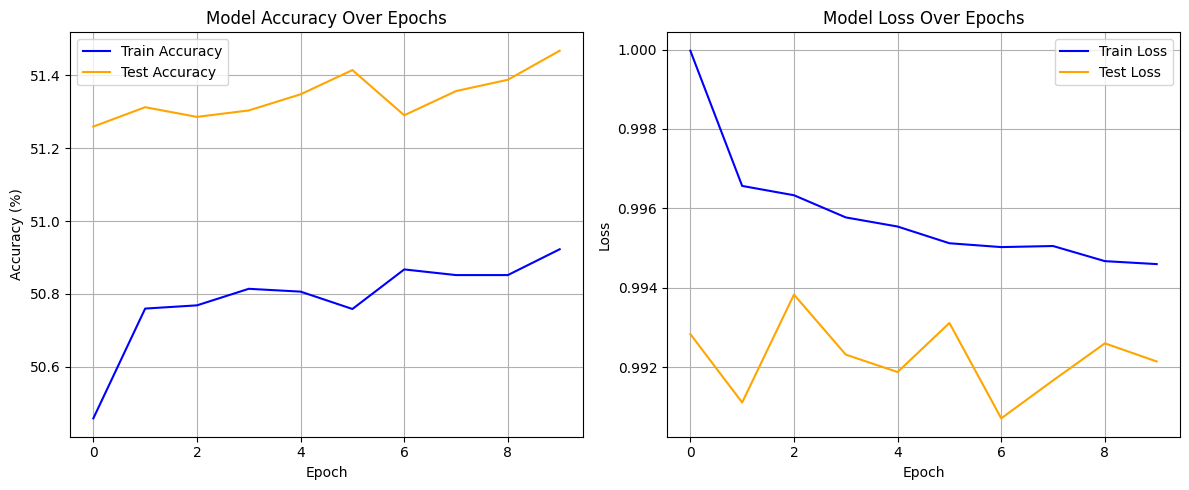

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(train_accs, label="Train Accuracy", color="blue")
plt.plot(test_accs, label="Test Accuracy", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Over Epochs")
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(test_losses, label="Test Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss Over Epochs")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import torch.nn.functional as F

# Put model in evaluation mode
model.eval()

with torch.no_grad():
    # Pass a batch of matches into the model
    outputs = model(batch_features)

    # Convert logits to probabilities
    probabilities = F.softmax(outputs, dim=1)

    # Example output for a single match: tensor([0.60, 0.25, 0.15])
    # This means: 60% chance Home Win, 25% chance Draw, 15% chance Away Win

In [ ]:
test_df['MatchDate'] = pd.to_datetime(test_df['MatchDate'])

# Isolate the 2024/2025 Premier League season
upcoming_df = test_df[(test_df['Division'] == 'E0') &
                      (test_df['MatchDate'] >= '2024-08-01') &
                      (test_df['MatchDate'] <= '2025-06-01')].copy()

# A full 20-team league season has exactly 380 matches
print(f"Matches isolated: {len(upcoming_df)}")

Matches isolated: 378


In [ ]:
# Extract ONLY your pre-match feature columns (e.g., HomeElo, OddHome)
features_unscaled = upcoming_df[feature_cols]

# Scale using the EXACT SAME scaler you fit on your training data
features_scaled = scaler.transform(features_unscaled)

# Convert to a PyTorch tensor
upcoming_features = torch.tensor(features_scaled, dtype=torch.float32)

In [ ]:
# Get a list of all 20 unique teams in this season
all_teams = pd.concat([upcoming_df['HomeTeam'], upcoming_df['AwayTeam']]).unique()

# Create a dictionary where every team starts at 0 points
starting_standings = {team: 0 for team in all_teams}

In [ ]:
model.eval()
with torch.no_grad():
    # Pass the scaled tensor (upcoming_features) through the model
    logits = model(upcoming_features)
    # Convert logits to probabilities and move to NumPy for the simulation loop
    match_probs = F.softmax(logits, dim=1).cpu().numpy()

# 2. Setup simulation variables
num_simulations = 10000
home_teams = upcoming_df['HomeTeam'].values
away_teams = upcoming_df['AwayTeam'].values

# simulation_results tracks where every team finishes across all 10,000 seasons
simulation_results = {team: [] for team in all_teams}

# 3. The Monte Carlo Loop
for sim in range(num_simulations):
    # Swap out 'current_standings' for 'starting_standings' so every team starts at 0 points
    season_points = starting_standings.copy()

    # Play every match in the isolated season
    for i in range(len(home_teams)):
        home = home_teams[i]
        away = away_teams[i]
        probs = match_probs[i] # e.g., [0.60, 0.25, 0.15]

        # 0 = Home Win, 1 = Draw, 2 = Away Win
        outcome = np.random.choice([0, 1, 2], p=probs)

        # Award points based on the simulated outcome
        if outcome == 0:
            season_points[home] += 3
        elif outcome == 1:
            season_points[home] += 1
            season_points[away] += 1
        else:
            season_points[away] += 3

    # Sort the league table by points (highest to lowest)
    sorted_table = sorted(season_points.items(), key=lambda x: x[1], reverse=True)

    # Record the final rank (1st, 2nd, 3rd...) for every team in this simulation
    for rank, (team, points) in enumerate(sorted_table, start=1):
        simulation_results[team].append(rank)

In [ ]:
def get_season_projections(team_name, results_dict, total_sims):
    # Check if the team actually exists in the isolated season
    if team_name not in results_dict:
        # Convert numeric ID back to string name for better error message
        decoded_team_name = team_encoder.inverse_transform([team_name])[0]
        print(f"Team '{decoded_team_name}' (ID: {team_name}) not found in the simulated season's results. Check your spelling or ensure they were in this specific season.")
        return

    # Extract the array of 10,000 ranks
    finishes = results_dict[team_name]

    # Calculate occurrences
    champions_count = finishes.count(1)
    top_four_count = sum(1 for rank in finishes if rank <= 4)
    relegation_count = sum(1 for rank in finishes if rank >= 18) # Ranks 18, 19, 20

    # Convert to percentages
    title_prob = (champions_count / total_sims) * 100
    top_four_prob = (top_four_count / total_sims) * 100
    relegation_prob = (relegation_count / total_sims) * 100

    # Calculate average finishing position
    avg_finish = sum(finishes) / total_sims

    # Output the statistics
    print(f"--- {team_encoder.inverse_transform([team_name])[0]} Projections ---") # Decode team name for output
    print(f"Average Finish: {avg_finish:.1f}")
    print(f"Title Odds:     {title_prob:.2f}%")
    print(f"Top 4 Odds:     {top_four_prob:.2f}%")
    print(f"Relegation:     {relegation_prob:.2f}%")
    print("-" * 30)

# --- Diagnostic Information ---
print("--- Available Team Names in LabelEncoder's Vocabulary ---")
print(sorted(team_encoder.classes_))
print("\n--- Teams present in the 2024/2025 Premier League Simulation ---")
# all_teams from A-nQNC35e0kr contains the encoded IDs of teams in upcoming_df
season_team_names = team_encoder.inverse_transform(all_teams)
print(sorted(season_team_names.tolist()))
print("\n")

# --- Original Code (with potential fix for team names) ---
# Ensure you use team names that are actually present and recognized by team_encoder
# If 'Arsenal' is not in the printed list above, you might need to adjust the string
arsenal_id = team_encoder.transform(['Arsenal'])[0]
everton_id = team_encoder.transform(['Everton'])[0]

# Call the function using your existing simulation variables
get_season_projections(arsenal_id, simulation_results, num_simulations)
get_season_projections(everton_id, simulation_results, num_simulations)


--- Available Team Names in LabelEncoder's Vocabulary ---
['A. Klagenfurt', 'A. Lustenau', 'A. Sebatspor', 'AC Oulu', 'AEK', 'AFC Eskilstuna', 'AFC Telford United', 'AFC Wimbledon', 'AIK', 'AVS', 'AZ Alkmaar', 'Aachen', 'Aalborg', 'Aalen', 'Aalesund', 'Aalst', 'Aarau', 'Aarhus', 'Aberdeen', 'Academica', 'Academica Clinceni', 'Academico Viseu', 'Accrington', 'Ad. Demirspor', 'Adanaspor', 'Admira', 'Ahlen', 'Airdrie', 'Airdrie Utd', 'Ajaccio', 'Ajaccio GFCO', 'Ajax', 'Ajax ', 'Akhisar Belediyespor', 'Akhmat Grozny', 'Akratitos', 'Akron Togliatti', 'Alanyaspor', 'Alaves', 'Albacete', 'Albinoleffe', 'Albion Rvs', 'Albirex Niigata', 'Alcorcon', 'Alcoyano', 'Aldershot', 'Aldosivi', 'Alessandria', 'Alfreton Town', 'Algeciras', 'Alicante', 'All Boys', 'Alloa', 'Almere City', 'Almeria', 'Altach', 'Altay', 'Altrincham', 'Alverca', 'Amedspor', 'America MG', 'Amiens', 'Amkar', 'Amorebieta', 'Ancona', 'Anderlecht', 'Andorra', 'Angers', 'Ankaragucu', 'Ankaraspor', 'Annan Athletic', 'Annecy', 'Antaly

In [ ]:
# Print all team names available in your results
print(sorted(list(simulation_results.keys())))

[np.int64(82), np.int64(87), np.int64(170), np.int64(180), np.int64(183), np.int64(242), np.int64(295), np.int64(371), np.int64(424), np.int64(551), np.int64(633), np.int64(650), np.int64(689), np.int64(690), np.int64(754), np.int64(768), np.int64(769), np.int64(1010), np.int64(1086), np.int64(1187), np.int64(1202)]


In [ ]:
# Calculate average rank for every team
table_summary = []
for team_id, ranks in simulation_results.items():
    team_name = team_encoder.inverse_transform([team_id])[0]
    avg_rank = sum(ranks) / num_simulations
    title_prob = (ranks.count(1) / num_simulations) * 100
    top4_prob = (sum(1 for r in ranks if r <= 4) / num_simulations) * 100
    relegation_prob = (sum(1 for r in ranks if r >= 18) / num_simulations) * 100

    table_summary.append({
        'Team': team_name,
        'Avg Finish': round(avg_rank, 2),
        'Title %': round(title_prob, 2),
        'Top 4 %': round(top4_prob, 2),
        'Relegation %': round(relegation_prob, 2)
    })

# Convert to DataFrame and sort by expected position
simulated_table = pd.DataFrame(table_summary).sort_values(by='Avg Finish').reset_index(drop=True)
simulated_table.index += 1  # 1-indexed table positions
simulated_table

,Team,Avg Finish,Title %,Top 4 %,Relegation %
1,Arsenal,2.44,40.00,88.19,0.00
2,Liverpool,2.56,29.60,89.17,0.00
3,Man City,3.29,19.14,77.68,0.00
4,Chelsea,5.05,5.23,48.64,0.01
5,Newcastle,6.90,1.99,24.84,0.09
6,Aston Villa,7.52,1.28,19.00,0.20
7,Brighton,8.33,0.74,13.36,0.42
8,Man United,8.97,0.58,11.13,0.52
9,Bournemouth,9.91,0.31,7.02,1.03
10,Fulham,10.19,0.39,7.01,1.54


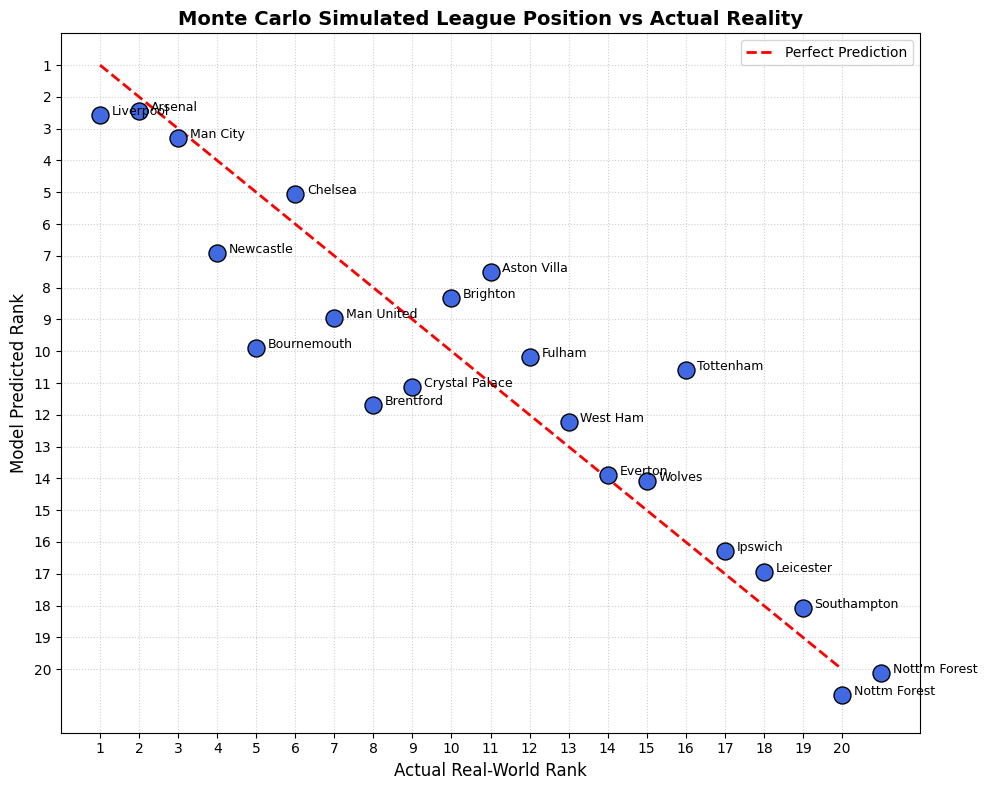

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate actual points from the historical match data
actual_points = {team: 0 for team in all_teams}

for _, row in upcoming_df.iterrows():
    # Use the encoded result column (0=Home Win, 1=Draw, 2=Away Win)
    result = row['FTResult_encoded']
    home = row['HomeTeam']
    away = row['AwayTeam']

    if result == 0:
        actual_points[home] += 3
    elif result == 1:
        actual_points[home] += 1
        actual_points[away] += 1
    elif result == 2:
        actual_points[away] += 3

# 2. Sort points to determine true final ranks
actual_sorted = sorted(actual_points.items(), key=lambda x: x[1], reverse=True)

# 3. Decode the team IDs back to text and assign integer ranks
actual_ranks_named = {
    team_encoder.inverse_transform([team_id])[0]: rank
    for rank, (team_id, pts) in enumerate(actual_sorted, start=1)
}

# 4. Map the actual ranks onto your simulated Pandas DataFrame
simulated_table['Actual Rank'] = simulated_table['Team'].map(actual_ranks_named)

# 5. Plot the comparison graph
plt.figure(figsize=(10, 8))

# Scatter actual rank vs predicted average finish
sns.scatterplot(
    data=simulated_table,
    x='Actual Rank',
    y='Avg Finish',
    s=150,
    color='royalblue',
    edgecolor='black',
    zorder=3
)

# Draw a diagonal line representing 100% perfect predictions
plt.plot([1, 20], [1, 20], color='red', linestyle='--', linewidth=2, label='Perfect Prediction', zorder=2)

# Label every single dot with the respective team name
for _, row in simulated_table.iterrows():
    plt.text(row['Actual Rank'] + 0.3, row['Avg Finish'], row['Team'], fontsize=9)

# Clean up axes and layout
plt.title('Monte Carlo Simulated League Position vs Actual Reality', fontsize=14, fontweight='bold')
plt.xlabel('Actual Real-World Rank', fontsize=12)
plt.ylabel('Model Predicted Rank', fontsize=12)
plt.xticks(range(1, 21))
plt.yticks(range(1, 21))
plt.xlim(0, 22)
plt.ylim(0, 22)

# Invert the Y-axis so 1st place is visually at the top of the graph
plt.gca().invert_yaxis()
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6, zorder=1)

plt.tight_layout()
plt.show()